# A* on the Ho Chi Minh City road network — checked and corrected version of `osm-astar.ipynb`

This notebook keeps the lecturer's model (OSM road graph, travel time with a time-dependent speed profile `speeds`)
and fixes the bugs found in `astar_shortest_path`. The original function is kept unchanged in section 3 so the two can be compared.

| # | Problem in the original code | Effect | Fix |
|---|---|---|---|
| B1 | `f_score_neighbor = g_score + h_score` uses the **current** node's g and h | the queue is not ordered by the neighbour's f, so the search is not A* | `f = g_neighbor + h_neighbor` |
| B2 | `t = t + ...` inside the neighbour loop | the clock of the current node grows with every neighbour scanned | compute `t_neighbor` from the current node's `t` |
| B3 | `speeds[math.floor(t)]` with `t` in minutes and only 20 slots | `IndexError` for any trip longer than 20 min (hidden today by B9) | cyclic profile, `speeds[slot % 20]` |
| B4 | Euclidean distance on (lon, lat) **degrees** divided by m/min | h ≈ 0.0001 min: no guidance, A* degenerates to Dijkstra | great-circle distance in metres |
| B5 | `h = d / speeds[t]` (speed at the current time) | over-estimates when later slots are faster ⇒ not admissible | divide by `max(speeds)` |
| B6 | `shortest_path_at_time` runs a full Dijkstra **per heuristic call** | ~50 ms per generated node; also not admissible (same as B5) | one reverse Dijkstra per destination, then O(1) look-ups |
| B7 | travel time of an edge uses only the speed at departure | a car departing later can arrive earlier (non-FIFO) ⇒ label-setting A* not exact | integrate the speed over the slots the edge spans |
| B8 | path list copied into every queue entry, no best-g check | O(path length) memory per entry, many useless duplicates | parent dictionary + best-g check |
| B9 | `graph[u]` of an OSMnx **MultiDiGraph** maps `v -> {key: attrs}`, so `edge_data.get('length', 1)` is always **1** | every edge costs 1 m: the code minimises the number of road segments, not distance or time (reported weight 0.34 min for a ~30 min trip) | take the minimum over parallel edges `d['length']` |
| B10 | returns `f_score` as the path weight | wrong value whenever h(goal) ≠ 0 or because of B1 | return the arrival time at the goal minus the start time |


In [1]:
import math, heapq, random, time
import numpy as np, pandas as pd, networkx as nx
from networkx.classes.function import path_weight
import matplotlib.pyplot as plt

## 1. Road graph
With internet access the whole city is downloaded with OSMnx, as in the original notebook.
Without it (as in our sandbox, where Nominatim is blocked and Overpass was overloaded) the notebook falls back to our graph of urban HCMC built from Geofabrik's Vietnam extract (`data_city/nodes.csv`, `data_city/edges.csv`),
converted to the same OSMnx-style `MultiDiGraph` (`x` = lon, `y` = lat, `length` in metres).

In [2]:
USE_OSMNX = True          # set False to use the local extract directly
LOCAL_DATA = '../data_city'  # folder with nodes.csv / edges.csv (urban HCMC, built from Geofabrik)
graph, source = None, None
if USE_OSMNX:
    try:
        import osmnx as ox
        ox.settings.requests_timeout = 30
        graph = ox.graph_from_place('Ho chi minh city', network_type='drive')
        source = 'OSMnx: Ho Chi Minh City (drive)'
    except Exception as e:
        print('OSMnx download not possible here:', type(e).__name__, str(e)[:120])
if graph is None:
    N = pd.read_csv(f'{LOCAL_DATA}/nodes.csv'); E = pd.read_csv(f'{LOCAL_DATA}/edges.csv')
    graph = nx.MultiDiGraph(crs='epsg:4326')
    for r in N.itertuples(): graph.add_node(int(r.id), x=r.lon, y=r.lat)
    for r in E.itertuples(): graph.add_edge(int(r.u), int(r.v), length=float(r.length_m))
    source = 'local graph of urban HCMC (Geofabrik extract)'
print(source, '-', graph.number_of_nodes(), 'nodes,', graph.number_of_edges(), 'edges')
NODES = np.array(list(graph.nodes)); LON = np.array([graph.nodes[n]['x'] for n in NODES]); LAT = np.array([graph.nodes[n]['y'] for n in NODES])

OSMnx download not possible here: ProxyError HTTPSConnectionPool(host='nominatim.openstreetmap.org', port=443): Max retries exceeded with url: /search?format=json&po


local graph of urban HCMC (Geofabrik extract) - 203396 nodes, 455837 edges


## 2. Time model, heuristics and the corrected A*

In [3]:
# speeds (metres per minute), one value per time slot -- the lecturer's profile
speeds = [350, 350, 500, 500, 600, 600, 550, 500, 400, 300, 600, 550, 500, 400, 300, 600, 550, 500, 400, 300]
SLOT = 1.0          # minutes per slot (the original indexes speeds[floor(t)] with t in minutes)
VMAX = max(speeds)

def speed_at(t):                                        # B3: cyclic profile, never out of range
    return speeds[int(math.floor(t / SLOT)) % len(speeds)]

def arrival(t, L):
    """Arrival time after driving L metres starting at time t (B7: FIFO, integrates across slots)."""
    while True:
        v = speed_at(t)
        slot_end = (math.floor(t / SLOT) + 1) * SLOT
        reach = v * (slot_end - t)
        if L <= reach: return t + L / v
        L -= reach; t = slot_end

def edge_length(u, v):                                  # B9: MultiDiGraph -> shortest parallel edge
    return min(d.get('length', math.inf) for d in graph[u][v].values())

def haversine_m(n1, n2):                                # B4: metres, not degrees
    a, b = graph.nodes[n1], graph.nodes[n2]
    p1, p2 = math.radians(a['y']), math.radians(b['y'])
    dp, dl = p2 - p1, math.radians(b['x'] - a['x'])
    h = math.sin(dp / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dl / 2) ** 2
    return 2 * 6371008.8 * math.asin(math.sqrt(h))

def euclidean_heuristic_fixed(n, dest, t=0):
    return haversine_m(n, dest) / VMAX                  # B5: admissible for every departure time

def make_exact_length_heuristic(dest):
    """B6: the idea of shortest_path_at_time, but one reverse Dijkstra per destination and admissible."""
    dist = nx.single_source_dijkstra_path_length(graph.reverse(copy=False), dest, weight='length')
    return lambda n, d, t=0: dist.get(n, math.inf) / VMAX

def astar_fixed(graph, origin, dest, heuristic=euclidean_heuristic_fixed, t0=0.0):
    """Time-dependent A*: minimises the arrival time when leaving `origin` at time t0."""
    if origin not in graph or dest not in graph: return None, None
    best = {origin: t0}; parent = {origin: None}; closed = set()
    open_set = [(t0 + heuristic(origin, dest, t0), t0, origin)]
    while open_set:
        f, t, u = heapq.heappop(open_set)
        if u in closed or t > best[u]: continue        # B8: skip outdated entries
        if u == dest:
            path = []
            while u is not None: path.append(u); u = parent[u]
            return path[::-1], t - t0                   # B10: real travel time
        closed.add(u)
        for v in graph[u]:
            if v in closed: continue
            tv = arrival(t, edge_length(u, v))          # B2: from the current node's own clock
            if tv < best.get(v, math.inf):
                best[v] = tv; parent[v] = u
                heapq.heappush(open_set, (tv + heuristic(v, dest, tv), tv, v))   # B1: neighbour's f
    return None, None

def nearest_node(lat, lon):
    return int(NODES[np.argmin((LAT - lat) ** 2 + ((LON - lon) * math.cos(math.radians(lat))) ** 2)])

## 3. The original function (unchanged) for comparison

In [4]:
def euclidean_heuristic(graph, node1, node2, t=0):
    pos1 = graph.nodes[node1]
    pos2 = graph.nodes[node2]
    return ( ((pos1['x'] - pos2['x'])**2 + (pos1['y'] - pos2['y'])**2)**0.5 ) / speeds[math.floor(t)]

def astar_shortest_path(graph, origin_node, destination_node, heuristic=euclidean_heuristic):
    if origin_node not in graph or destination_node not in graph:
        return None, None
    if origin_node == destination_node:
        return [origin_node], 0
    g_score = 0
    h_score = heuristic( origin_node, destination_node, 0 )
    open_set = [(g_score + h_score, g_score, 0, h_score, origin_node, [origin_node])]
    closed_set = set()
    while open_set:
        f_score, g_score, t, h_score, current_node, path = heapq.heappop(open_set)
        if current_node == destination_node:
            return path, f_score
        if current_node in closed_set:
            continue
        closed_set.add(current_node)
        for neighbor, edge_data in graph[current_node].items():
            if neighbor in closed_set:
                continue
            g_score_neighbor = g_score + edge_data.get('length', 1) / speeds[math.floor(t)]
            t = t + edge_data.get('length', 1) / speeds[math.floor(t)]
            h_score_neighbor = heuristic( neighbor, destination_node, t )
            f_score_neighbor = g_score + h_score
            heapq.heappush(open_set, (f_score_neighbor, g_score_neighbor, t, h_score_neighbor, neighbor, path + [neighbor]))
    return None, None

u0 = next(iter(graph.nodes)); v0 = next(iter(graph[u0]))
print('graph[u][v] =', dict(graph[u0][v0]), " ->  edge_data.get('length', 1) =", graph[u0][v0].get('length', 1))

graph[u][v] = {0: {'length': 13.106}}  ->  edge_data.get('length', 1) = 1


## 4. Correctness test
The speed is the same on every road at a given moment and the travel-time model is FIFO, so the fastest route is the
**shortest-length route**, and its travel time is `arrival(t0, L*) - t0`. This gives an independent oracle.
We also compare with the uninformed search (h = 0, time-dependent Dijkstra).

In [5]:
random.seed(2026)
pairs = [tuple(random.sample(list(graph.nodes), 2)) for _ in range(60)]
rows, crashes = [], 0
for a, b in pairs:
    t0 = random.choice([0.0, 3.7, 9.2, 14.5])
    sp = nx.shortest_path(graph, a, b, weight='length'); L = path_weight(graph, sp, 'length')
    oracle = arrival(t0, L) - t0
    p1, w1 = astar_fixed(graph, a, b, euclidean_heuristic_fixed, t0)
    p0, w0 = astar_fixed(graph, a, b, lambda n, d, t=0: 0.0, t0)
    try:
        pt, wt = astar_shortest_path(graph, a, b, heuristic=lambda n1, n2, t: euclidean_heuristic(graph, n1, n2, t))
        Lt = sum(edge_length(x, y) for x, y in zip(pt, pt[1:]))
    except IndexError:
        crashes += 1; Lt, wt = math.nan, math.nan
    L1 = sum(edge_length(x, y) for x, y in zip(p1, p1[1:]))
    rows.append(dict(oracle_min=oracle, fixed_min=w1, dijkstra_min=w0, fixed_len_m=L1, opt_len_m=L,
                     original_len_m=Lt, original_reported=wt))
df = pd.DataFrame(rows)
print('fixed A* == oracle on all pairs         :', np.allclose(df.fixed_min, df.oracle_min, rtol=1e-9))
print('fixed A* == time-dependent Dijkstra      :', np.allclose(df.fixed_min, df.dijkstra_min, rtol=1e-9))
print('original: route length / optimum (mean, max): %.3f, %.3f' % ((df.original_len_m / df.opt_len_m).mean(), (df.original_len_m / df.opt_len_m).max()))
print('original: reported weight (mean) %.3f min  vs  true travel time (mean) %.1f min' % (df.original_reported.mean(), df.oracle_min.mean()))
print('original: IndexError crashes            :', crashes)
df.describe().loc[['mean', 'min', 'max']].round(3)

fixed A* == oracle on all pairs         : True
fixed A* == time-dependent Dijkstra      : True
original: route length / optimum (mean, max): 1.257, 2.169
original: reported weight (mean) 0.481 min  vs  true travel time (mean) 37.8 min
original: IndexError crashes            : 0


,oracle_min,fixed_min,dijkstra_min,fixed_len_m,opt_len_m,original_len_m,original_reported
mean,37.789,37.789,37.789,17729.104,17729.104,22513.960,0.481
min,3.435,3.435,3.435,1767.685,1767.685,2033.023,0.097
max,94.989,94.989,94.989,44775.495,44775.495,61063.196,0.914


**B3 is only hidden by B9.** If we fix only the edge length (B9) in the original function, the clock `t` reaches real
travel times and `speeds[math.floor(t)]` runs past the 20 slots:

In [6]:
def original_with_only_B9_fixed(graph, o, d):
    open_set = [(0, 0, 0, o)]; closed = set()
    while open_set:
        f, g, t, u = heapq.heappop(open_set)
        if u == d: return g
        if u in closed: continue
        closed.add(u)
        for v in graph[u]:
            L = edge_length(u, v)
            g2 = g + L / speeds[math.floor(t)]
            t = t + L / speeds[math.floor(t)]
            heapq.heappush(open_set, (g2, g2, t, v))
a, b = max(pairs, key=lambda p: haversine_m(*p))
try:
    original_with_only_B9_fixed(graph, a, b); print('no crash')
except IndexError as e:
    print('IndexError:', e)

IndexError: list index out of range


## 5. Effort of the heuristics (B4, B6)

In [7]:
a, b = max(pairs, key=lambda p: haversine_m(*p))
def count(h):
    n = [0]
    def hh(x, y, t=0): n[0] += 1; return h(x, y, t)
    t1 = time.time(); p, w = astar_fixed(graph, a, b, hh, 0.0); return w, n[0], (time.time() - t1) * 1e3
h_exact = make_exact_length_heuristic(b)
for name, h in [('h = 0 (Dijkstra)', lambda x, y, t=0: 0.0),
                ('Euclidean on degrees (original B4)', lambda x, y, t=0: euclidean_heuristic(graph, x, y, 0)),
                ('great-circle / v_max (fixed)', euclidean_heuristic_fixed),
                ('exact remaining length / v_max (B6 fixed)', h_exact)]:
    w, n, ms = count(h)
    print(f'{name:42s} travel time {w:7.3f} min, heuristic calls {n:6d}, {ms:7.1f} ms')
t1 = time.time(); nx.shortest_path(graph, a, b, weight='length'); one = (time.time() - t1) * 1e3
print(f'original shortest_path_at_time(): {one:.1f} ms per call -> x {count(euclidean_heuristic_fixed)[1]} calls')

h = 0 (Dijkstra)                           travel time  86.291 min, heuristic calls 198722,   890.1 ms


Euclidean on degrees (original B4)         travel time  86.291 min, heuristic calls 198718,  1039.1 ms


great-circle / v_max (fixed)               travel time  86.291 min, heuristic calls 121540,   687.2 ms


exact remaining length / v_max (B6 fixed)  travel time  86.291 min, heuristic calls  87098,   424.2 ms


original shortest_path_at_time(): 624.9 ms per call -> x 121540 calls


## 6. Example route

depart at t =  0.0 min: 330 nodes, 19068 m, 41.05 min
depart at t =  9.0 min: 330 nodes, 19068 m, 41.11 min


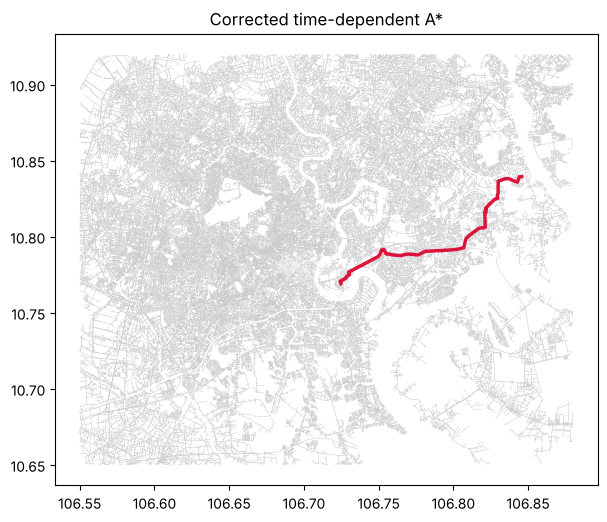

In [8]:
o, d = (10.768856, 106.725019), (10.839613, 106.845798)    # the lecturer's example
on, dn = nearest_node(*o), nearest_node(*d)
for t0 in [0.0, 9.0]:
    p, w = astar_fixed(graph, on, dn, euclidean_heuristic_fixed, t0)
    print(f'depart at t = {t0:4.1f} min: {len(p)} nodes, {sum(edge_length(x, y) for x, y in zip(p, p[1:])):.0f} m, {w:.2f} min')
from matplotlib.collections import LineCollection
fig, ax = plt.subplots(figsize=(7, 6))
segs = [[(graph.nodes[u]['x'], graph.nodes[u]['y']), (graph.nodes[v]['x'], graph.nodes[v]['y'])] for u, v in graph.edges()]
ax.add_collection(LineCollection(segs, colors='#cccccc', linewidths=0.2)); ax.autoscale()
ax.plot([graph.nodes[n]['x'] for n in p], [graph.nodes[n]['y'] for n in p], color='crimson', lw=2.5)
ax.set_aspect(1 / math.cos(math.radians(10.78))); ax.set_title('Corrected time-dependent A*'); plt.show()